# A Color Histogram Baseline for Fruit and Vegetable Classification

**Project question.** How well can a simple model recognize nine kinds of food using color alone?

EDA identified 2,003 photos across nine target classes. Apple varieties share the label `apple`, and potato varieties share `potato`. Many photos have large areas of background. That gives us our first experiment: does skipping background-colored pixels help the model recognize the food?

**Presentation path**

1. Start with the shared split and turn each photo into 96 color features.
2. Compare the three masks, check the choice across folds, and look at what the model learned.
3. Test PCA and both crop methods using the original Mask 80 as a reference.
4. Check what the corners and capture times can tell us about the scores.
5. Close with the original baseline's test result and the files the group can reuse.

A **baseline** is the reference model the group compares against. Here it is logistic regression using color histograms. Run from top to bottom to reproduce the tables and figures, or use the saved outputs for the presentation.

## 1. Use the Shared Split

`data/dataset_split.csv` gives us the image path, the correct food label, and the split. The image paths are relative to the project root.

| Split | Photos | Role |
|---|---:|---|
| Training | 1,603 | Fit the model |
| Validation | 200 | Compare preprocessing choices |
| Test | 200 | Report the selected baseline's final score |

Think of training as practice, validation as a trial exam, and test as the final exam. Using the same photos in each split makes the group's scores comparable.

In [1]:
import sys
from pathlib import Path

import numpy as np
from PIL import Image
from IPython.display import display

project_folder = Path.cwd()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

if str(project_folder) not in sys.path:
    sys.path.insert(0, str(project_folder))

In [2]:
import pandas as pd

split_path = project_folder / "data" / "dataset_split.csv"
split_table = pd.read_csv(split_path)

experiment_rows = split_table[split_table["split"].isin(["train", "validation"])]
is_training = experiment_rows["split"].eq("train").to_numpy()
labels = experiment_rows["target_class"].to_numpy()

print("Training photos:", is_training.sum())
print("Validation photos:", (~is_training).sum())
display(experiment_rows.head(3))

Training photos: 1603
Validation photos: 200


,image_path,target_class,split
200,data/raw_images/fuji_apple/fuji_apple_001.jpg,apple,train
201,data/raw_images/fuji_apple/fuji_apple_003.jpg,apple,train
202,data/raw_images/fuji_apple/fuji_apple_004.jpg,apple,train


## 2. Turn Each Photo into 96 Color Features

### 2.1 Count Color Intensities

An RGB pixel has three values, one each for red, green, and blue. A histogram sorts pixel values into buckets. For example, the first red bucket counts red values from 0 to 7 and the second counts values from 8 to 15. We divide each count by its total to get the share of pixels in that bucket.

```text
1 photo → 32 red shares + 32 green shares + 32 blue shares → 96 features
```

Each photo becomes one row, with its correct food label alongside it. The histogram keeps the color distribution and loses pixel positions. An apple on the left can have a similar histogram to an apple on the right. We chose histograms for the baseline because they give a compact color description that can still be useful when the food moves within the frame.

### 2.2 Decide Which Pixels to Count

Following the EDA method, we estimate the background color from four patches at the corners of the original photo. **Color distance** measures how different a pixel is from that estimated background, using its RGB values.

| Version | Pixels counted |
|---|---|
| Whole image | Every pixel |
| Mask 65 | Pixels more than 65 color-distance units from the background |
| Mask 80 | Pixels more than 80 color-distance units from the background |

A pixel at distance **70** is counted by Mask 65 and skipped by Mask 80. The higher cutoff skips a wider range of colors, which can include food pixels. When a mask skips every pixel, we count the whole photo so it stays in the comparison.

#### Mask 80 on one training photo

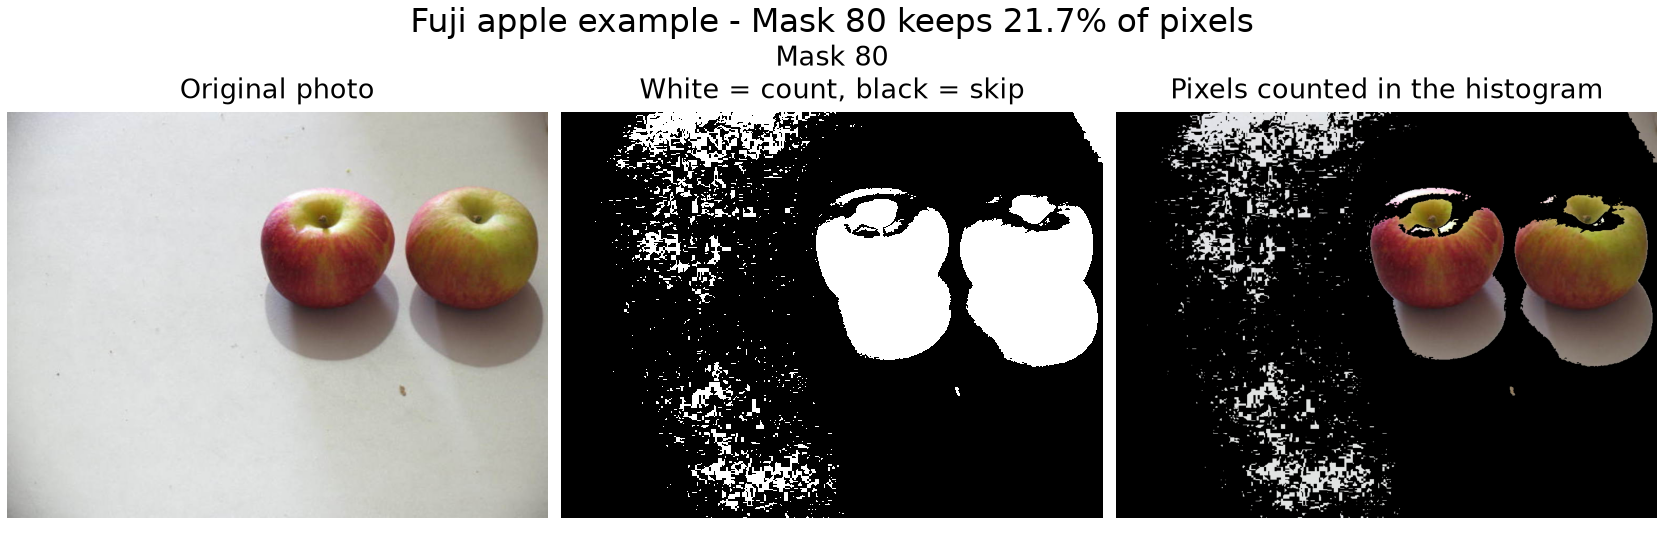

White pixels in the middle panel go into the color counts. Mask 80 kept **21.7%** of this photo's pixels. It kept some table and shadow pixels and skipped some bright areas of the apples. The right panel shows the original colors of the pixels that were counted.

In [3]:
def rgb_histogram_features(pixels):
    channel_histograms = []

    for channel in range(3):
        counts, _ = np.histogram(pixels[:, channel], bins=32, range=(0, 256))
        channel_histograms.append(counts / counts.sum())

    return np.concatenate(channel_histograms)


def background_color_distance(image):
    height, width, _ = image.shape
    corner_height = max(1, int(height * 0.10))
    corner_width = max(1, int(width * 0.10))

    corners = [
        image[:corner_height, :corner_width],
        image[:corner_height, -corner_width:],
        image[-corner_height:, :corner_width],
        image[-corner_height:, -corner_width:]
    ]
    corner_pixels = np.concatenate([corner.reshape(-1, 3) for corner in corners])
    background_color = np.median(corner_pixels, axis=0).astype(np.uint8)

    pixels = image.reshape(-1, 3).astype(np.float32)
    difference = pixels - background_color.astype(np.float32)
    return np.linalg.norm(difference, axis=1)

In [4]:
thresholds = {"Whole image": None, "Mask 65": 65, "Mask 80": 80}
feature_rows = {name: [] for name in thresholds}
empty_mask_counts = {name: 0 for name in thresholds if thresholds[name] is not None}

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        image = np.array(source.convert("RGB"))

    pixels = image.reshape(-1, 3)
    whole_image_features = rgb_histogram_features(pixels)
    color_distance = background_color_distance(image)

    for name, threshold in thresholds.items():
        features = whole_image_features
        if threshold is not None:
            selected_pixels = pixels[color_distance > threshold]
            if len(selected_pixels) > 0:
                features = rgb_histogram_features(selected_pixels)
            else:
                empty_mask_counts[name] += 1

        feature_rows[name].append(features)

feature_tables = {name: np.array(rows) for name, rows in feature_rows.items()}
for name, X in feature_tables.items():
    print(name, "- training shape", X[is_training].shape,
          "- validation shape", X[~is_training].shape)

print("Empty masks that used the whole image:", empty_mask_counts)

Whole image - training shape (1603, 96) - validation shape (200, 96)
Mask 65 - training shape (1603, 96) - validation shape (200, 96)
Mask 80 - training shape (1603, 96) - validation shape (200, 96)
Empty masks that used the whole image: {'Mask 65': 9, 'Mask 80': 17}


## 3. Choose the Baseline on Validation

### 3.1 Compare the Three Versions

#### Learning note – From two answers to nine

**Binary logistic regression** is like a quiz with two buttons. It could answer “apple” or “not apple.” A kiwi and a potato would both go under “not apple.” Our quiz has nine buttons, one for each food class, and each photo has one correct answer. Scikit-learn's `LogisticRegression` uses **multinomial logistic regression** for this setup.

1. **Read the photo's 96 color features.** They tell the model how common different color intensities are in the photo.
2. **Give each food a score.** During training, the model learns which color features raise or lower each food's score. It uses those weights to calculate nine scores for a new photo.
3. **Turn the scores into probabilities and pick the largest.** This conversion is called **softmax**. The nine probabilities add up to 100%.

Here is a made-up result for one photo:

| Food | Example probability |
|---|---:|
| Apple | **62%** |
| Nectarine | 18% |
| Kiwi | 10% |
| Plum | 3% |
| Potato | 2% |
| Spanish pear | 2% |
| Onion | 1% |
| Honeydew melon | 1% |
| Watermelon | 1% |

The model predicts **apple** because apple has the highest score and therefore the highest probability. When we check the prediction against the photo's actual label, we can count it as a correct guess or a mistake.

The three versions below use the same model settings and split.

**Accuracy** is the share of photos classified correctly. **Macro-F1** gives each food its own score, then averages the scores equally. Each food's F1 balances how many of its photos we find and how often guesses of that food are right. We use macro-F1 as our main selection metric because the app predicts one food and we want all nine classes to count equally.

**ROC-AUC** measures how well the model ranks photos. For example, kiwi's AUC measures how often an actual kiwi photo gets a higher kiwi probability than a photo of another food, with ties counted as half. We repeat that comparison for each food against the other eight, then average all nine scores equally. This is **macro one-vs-rest ROC-AUC**. We report it alongside accuracy and macro-F1. A true onion can get a higher onion probability than most other photos, which helps AUC, while potato still gets the top probability for that photo, which hurts onion F1.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def macro_ovr_auc(model, features, actual_labels):
    """Average one-vs-rest ROC-AUC across the model's food classes."""
    probabilities = model.predict_proba(features)
    return roc_auc_score(
        actual_labels, probabilities, labels=model.classes_,
        multi_class="ovr", average="macro"
    )

validation_results = []
validation_predictions = {}
for name, X in feature_tables.items():
    X_train = X[is_training]
    y_train = labels[is_training]
    X_validation = X[~is_training]
    y_validation = labels[~is_training]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train, y_train)
    predictions = model.predict(X_validation)
    validation_predictions[name] = predictions

    validation_results.append({
        "Image preparation": name,
        "Accuracy": accuracy_score(y_validation, predictions),
        "Macro-F1": f1_score(y_validation, predictions, average="macro", zero_division=0),
        "ROC-AUC": macro_ovr_auc(model, X_validation, y_validation)
    })

validation_scores = pd.DataFrame(validation_results)
display(validation_scores.round(4))

,Image preparation,Accuracy,Macro-F1,ROC-AUC
0,Whole image,0.715,0.5795,0.9237
1,Mask 65,0.730,0.6401,0.9392
2,Mask 80,0.720,0.6648,0.9419


### 3.2 See Which Foods the Masks Confuse

A confusion matrix is a tally sheet. Pick the actual food on the left and read across to see the guesses. An onion guessed as potato adds one tally to the onion row and potato column. The diagonal shows correct guesses. The two charts share the same class order and color scale.

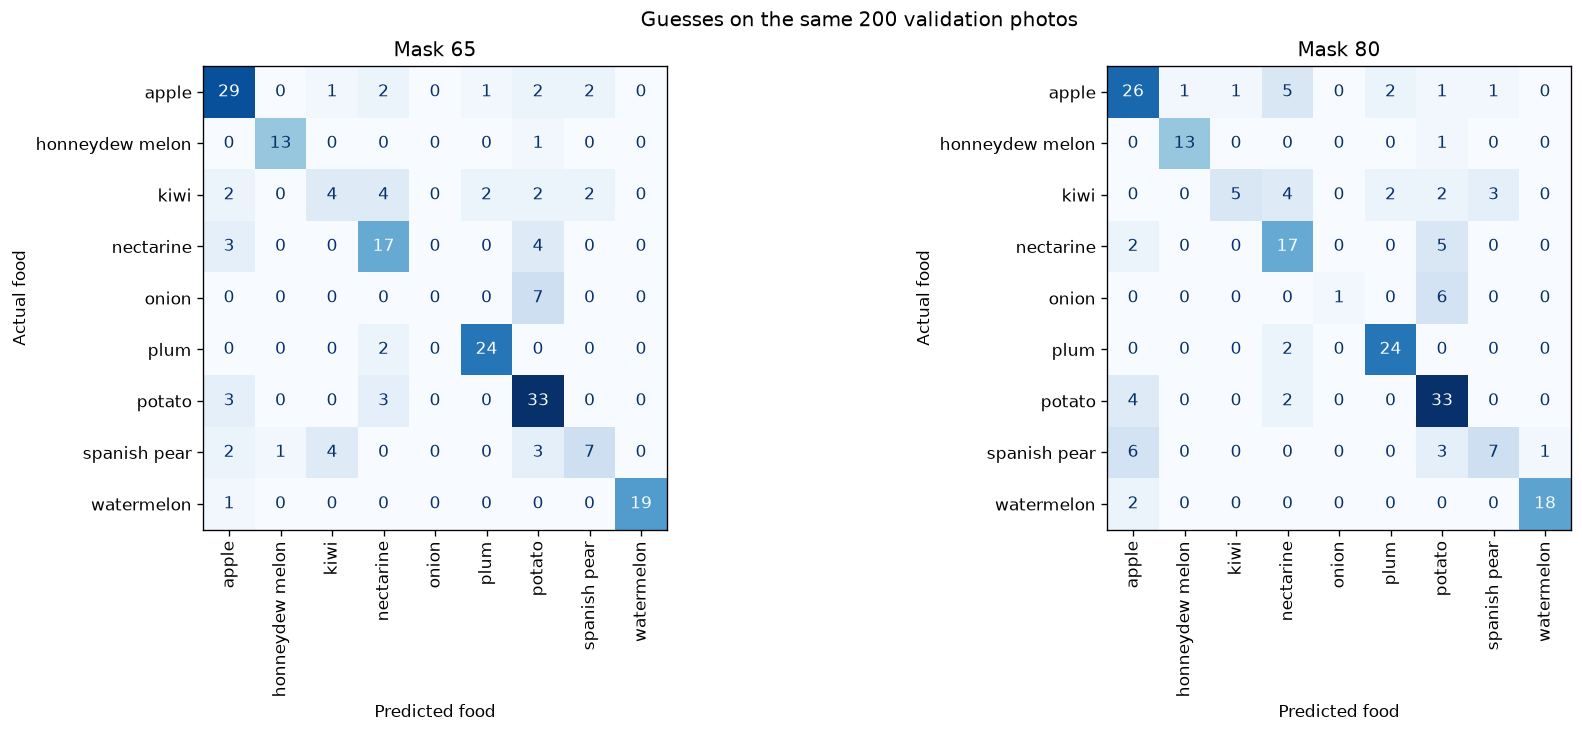

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

mask_names = ["Mask 65", "Mask 80"]
class_names = sorted(set(y_validation))
display_names = [name.replace("_", " ") for name in class_names]
confusion_counts = {}

for name in mask_names:
    confusion_counts[name] = confusion_matrix(
        y_validation, validation_predictions[name], labels=class_names
    )

max_count = max(matrix.max() for matrix in confusion_counts.values())
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")

for name, ax in zip(mask_names, axes):
    matrix_plot = ConfusionMatrixDisplay(
        confusion_counts[name], display_labels=display_names
    )
    matrix_plot.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90)
    matrix_plot.im_.set_clim(0, max_count)
    ax.set_title(name)
    ax.set_xlabel("Predicted food")
    ax.set_ylabel("Actual food")

fig.suptitle("Guesses on the same 200 validation photos")
plt.show()
plt.close(fig)

The table shows each food's F1 and how many validation photos it had. The last column gives the change from Mask 65 to Mask 80.

In [7]:
per_class_scores = pd.DataFrame({
    "Food": display_names,
    "Validation photos": confusion_counts["Mask 65"].sum(axis=1)
})

for name in mask_names:
    per_class_scores[f"F1 {name}"] = f1_score(
        y_validation,
        validation_predictions[name],
        labels=class_names,
        average=None,
        zero_division=0
    )

per_class_scores["F1 change (80 minus 65)"] = (
    per_class_scores["F1 Mask 80"] - per_class_scores["F1 Mask 65"]
)
display(per_class_scores.round(3))

,Food,Validation photos,F1 Mask 65,F1 Mask 80,F1 change (80 minus 65)
0,apple,37,0.753,0.675,-0.078
1,honneydew melon,14,0.929,0.929,0.000
2,kiwi,16,0.320,0.455,0.135
3,nectarine,24,0.654,0.630,-0.024
4,onion,7,0.000,0.250,0.250
5,plum,26,0.906,0.889,-0.017
6,potato,39,0.725,0.733,0.008
7,spanish pear,17,0.500,0.500,0.000
8,watermelon,20,0.974,0.923,-0.051


#### First Choice – Mask 80

Mask 65 got **146 of 200** photos right. Mask 80 got **144** right and had the higher macro-F1, **0.665 versus 0.640**. Its biggest F1 gains were on onion and kiwi. Mask 80 correctly identified one of the seven onion photos, which raised onion's F1 from 0 to 0.250. Apple F1 fell from 0.753 to 0.675.

We selected **Mask 80 with all 96 features and default weights** using validation macro-F1. The difference is small and the onion result rests on seven photos. That gives us a reason to check the comparison across more folds.

Validation ROC-AUC was **0.924** for the whole image, **0.939** for Mask 65, and **0.942** for Mask 80.

### 3.3 Does the Mask Choice Hold Up Across Folds?

#### Learning note – Take turns being the trial exam

We divide the 1,603 training photos into five folds with similar food proportions. We train on four folds and score on the fifth, then rotate. Each photo gets one turn as an unseen example. All six settings use the same folds. The mean macro-F1 summarizes the five scores. The standard deviation shows how much the scores varied between folds.

We compare whole-image, Mask 65, and Mask 80 histograms with default and balanced class weights. Balanced weights give mistakes on rarer foods more influence during fitting. The weights are calculated from the four fitting folds each time. The per-food table combines the held-out guesses from all five folds for Mask 80, so we can see which foods gained or lost F1 when weights changed.

The tables also show mean ROC-AUC and its standard deviation across the five held-out folds. We calculate AUC separately within each fold using its fitted model and held-out probabilities.

In [17]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from src.evaluate import evaluate_predictions

review_rows = experiment_rows.loc[is_training]
review_labels = labels[is_training]
review_class_names = sorted(split_table["target_class"].unique())
review_features = {name: table[is_training] for name, table in feature_tables.items()}
review_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
review_folds = list(review_splitter.split(review_features["Mask 80"], review_labels))


def score_review_folds(estimator, features, folds):
    fold_scores = []
    held_out_guesses = np.empty_like(review_labels)

    for fit_indices, score_indices in folds:
        fold_model = clone(estimator)
        fold_model.fit(features[fit_indices], review_labels[fit_indices])
        guesses = fold_model.predict(features[score_indices])
        held_out_guesses[score_indices] = guesses

        scores = evaluate_predictions(review_labels[score_indices], guesses, review_class_names)
        auc = macro_ovr_auc(fold_model, features[score_indices], review_labels[score_indices])
        fold_scores.append([scores["accuracy"], scores["macro_f1"], auc])

    return np.array(fold_scores), held_out_guesses


weight_options = {"Default": None, "Balanced": "balanced"}
review_results = []
review_guesses = {}
for name, features in review_features.items():
    for weight_name, class_weight in weight_options.items():
        review_model = LogisticRegression(max_iter=1000, class_weight=class_weight)
        fold_scores, guesses = score_review_folds(review_model, features, review_folds)
        review_guesses[(name, weight_name)] = guesses
        onion_f1 = f1_score(review_labels, guesses, labels=["onion"], average=None, zero_division=0)[0]
        review_results.append({
            "Image preparation": name,
            "Class weights": weight_name,
            "Mean accuracy": fold_scores[:, 0].mean(),
            "Mean macro-F1": fold_scores[:, 1].mean(),
            "Macro-F1 SD": fold_scores[:, 1].std(ddof=1),
            "Mean ROC-AUC": fold_scores[:, 2].mean(),
            "ROC-AUC SD": fold_scores[:, 2].std(ddof=1),
            "Onion F1 (pooled)": onion_f1
        })

review_comparison = pd.DataFrame(review_results).sort_values("Mean macro-F1", ascending=False)
display(review_comparison.round(3).reset_index(drop=True))

mask_80_class_f1 = pd.DataFrame({"Food": review_class_names})
for weight_name in weight_options:
    mask_80_class_f1[f"F1 {weight_name}"] = f1_score(
        review_labels, review_guesses[("Mask 80", weight_name)],
        labels=review_class_names, average=None, zero_division=0
    )
display(mask_80_class_f1.round(3))

,Image preparation,Class weights,Mean accuracy,Mean macro-F1,Macro-F1 SD,Mean ROC-AUC,ROC-AUC SD,Onion F1 (pooled)
0,Mask 65,Balanced,0.664,0.657,0.010,0.945,0.005,0.502
1,Mask 80,Balanced,0.662,0.654,0.015,0.943,0.003,0.550
2,Mask 80,Default,0.728,0.643,0.024,0.945,0.004,0.125
3,Whole image,Balanced,0.673,0.641,0.037,0.932,0.012,0.546
4,Mask 65,Default,0.725,0.639,0.017,0.947,0.006,0.000
5,Whole image,Default,0.669,0.544,0.031,0.933,0.011,0.000


,Food,F1 Default,F1 Balanced
0,apple,0.742,0.462
1,honneydew_melon,0.832,0.810
2,kiwi,0.385,0.441
3,nectarine,0.671,0.628
4,onion,0.125,0.550
5,plum,0.885,0.868
6,potato,0.755,0.642
7,spanish_pear,0.538,0.595
8,watermelon,0.863,0.887


**What changed across folds.** With default weights, Mask 65 and Mask 80 were close in mean macro-F1 (**0.639** and **0.643**). Balancing weights raised Mask 80's pooled onion F1 from **0.125 to 0.550**. Across all six settings, balanced Mask 65 had the highest mean macro-F1 (**0.657**) and default-weight Mask 65 had the highest mean ROC-AUC (**0.947**). The gap between the two balanced masks was small relative to their variation across folds.

The group comparison keeps the original default-weight Mask 80 baseline from Section 3.2. The fold results show how much the choice can depend on weighting and the metric.

### 3.4 Which Colors Drive the Predictions?

#### Learning note – See what pushes each food's score up or down

Each row is a food and each square is one color-intensity bucket. A positive coefficient pushes that food's score up as the bucket's share increases. A negative coefficient pushes it down. For example, a positive weight for a bright green bucket would mean that bucket supports the model's score for the food. The heatmap shows what the model actually learned from these photos.

For the heatmap, we fit Mask 65 with balanced weights on all training photos. It had the highest mean macro-F1 in the fold comparison above. The color buckets work together. A strong coefficient can reflect the food, the background, or the lighting in the training photos.

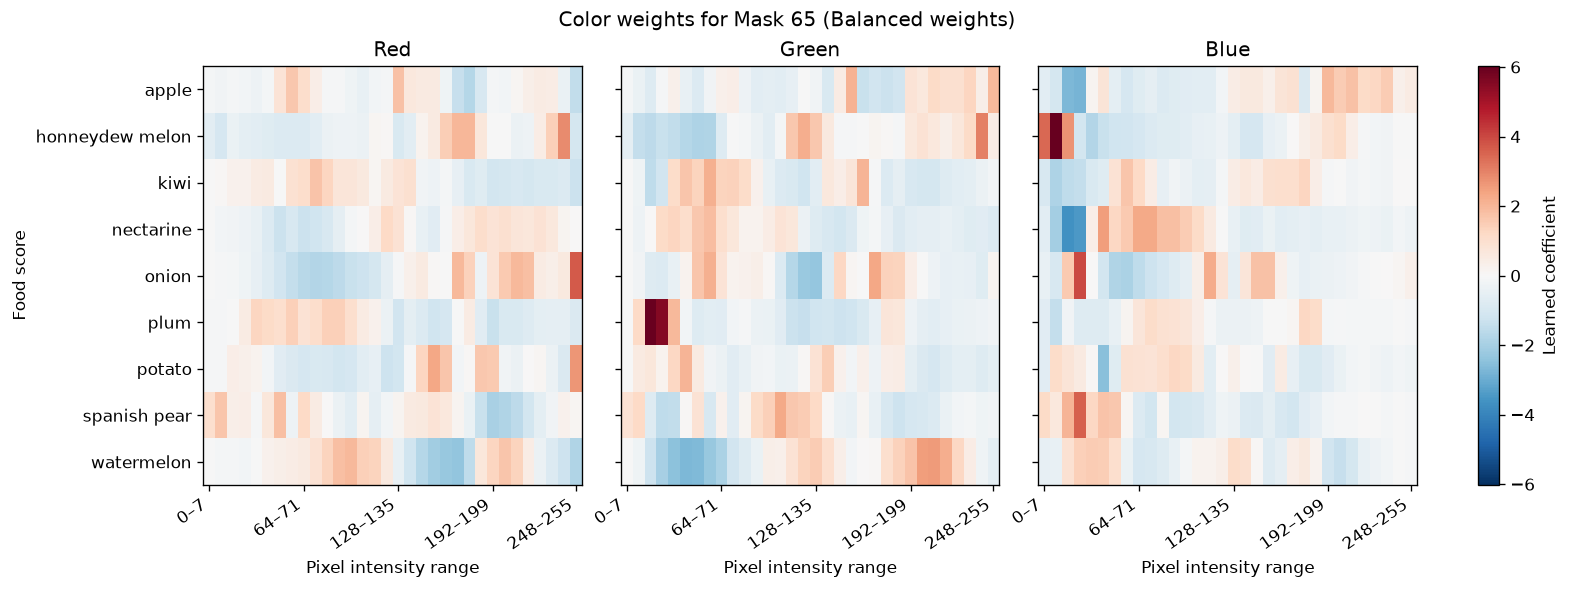

,Food,Strongest positive channel,Intensity range,Coefficient
0,apple,Green,152–159,2.080
1,onion,Blue,24–31,3.968


In [18]:
import matplotlib.pyplot as plt

best_review = review_comparison.iloc[0]
interpretation_features = review_features[best_review["Image preparation"]]
interpretation_model = LogisticRegression(
    max_iter=1000, class_weight=weight_options[best_review["Class weights"]]
)
interpretation_model.fit(interpretation_features, review_labels)
weights = interpretation_model.coef_
weight_limit = np.abs(weights).max()
channels = ["Red", "Green", "Blue"]
bin_ticks = [0, 8, 16, 24, 31]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True, layout="constrained")

for channel_index, (channel, ax) in enumerate(zip(channels, axes)):
    start = 32 * channel_index
    image = ax.imshow(weights[:, start:start + 32], cmap="RdBu_r", aspect="auto",
                      vmin=-weight_limit, vmax=weight_limit)
    ax.set_title(channel)
    ax.set_xticks(bin_ticks, [f"{8 * b}–{8 * b + 7}" for b in bin_ticks], rotation=35, ha="right")
    ax.set_xlabel("Pixel intensity range")
    ax.set_yticks(range(len(interpretation_model.classes_)),
                  [name.replace("_", " ") for name in interpretation_model.classes_])

axes[0].set_ylabel("Food score")
fig.colorbar(image, ax=axes, label="Learned coefficient")
fig.suptitle(f"Color weights for {best_review['Image preparation']} ({best_review['Class weights']} weights)")
plt.show()
plt.close(fig)

weight_examples = []
for food in ["apple", "onion"]:
    row = list(interpretation_model.classes_).index(food)
    feature = weights[row].argmax()
    channel, color_bin = divmod(feature, 32)
    weight_examples.append({
        "Food": food,
        "Strongest positive channel": channels[channel],
        "Intensity range": f"{8 * color_bin}–{8 * color_bin + 7}",
        "Coefficient": weights[row, feature]
    })
display(pd.DataFrame(weight_examples).round(3))

**Reading the heatmap.** For apple, the strongest positive coefficient was in the **green 152–159** bucket. For onion, it was in the **blue 24–31** bucket. The model learned those patterns from the photos. The corner experiment in Section 6 checks whether the photo setup could also be carrying some of the color signal.

## 4. Can PCA Shorten the Color Description?

PCA combines the 96 color columns into fewer columns called **principal components**. Imagine several color buckets that tend to rise and fall together. One combined number can capture much of that shared pattern. Each row still represents the same photo.

We fit PCA on training features and keep enough components to explain at least 95% of their variation. Then we apply those same combinations to validation features. The table shows what happened to the rows and columns.

In [8]:
from sklearn.decomposition import PCA

mask_80_features = feature_tables["Mask 80"]
X_train_mask_80 = mask_80_features[is_training]
X_validation_mask_80 = mask_80_features[~is_training]
y_train_mask_80 = labels[is_training]
y_validation_mask_80 = labels[~is_training]

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_mask_80)
X_validation_pca = pca.transform(X_validation_mask_80)

shape_comparison = pd.DataFrame([
    {
        "Split": "Training",
        "Photos": X_train_mask_80.shape[0],
        "Columns before PCA": X_train_mask_80.shape[1],
        "Columns after PCA": X_train_pca.shape[1]
    },
    {
        "Split": "Validation",
        "Photos": X_validation_mask_80.shape[0],
        "Columns before PCA": X_validation_mask_80.shape[1],
        "Columns after PCA": X_validation_pca.shape[1]
    }
])
display(shape_comparison)
print(f"Training variation explained: {pca.explained_variance_ratio_.sum():.1%}")

Training variation explained: 95.2%


,Split,Photos,Columns before PCA,Columns after PCA
0,Training,1603,96,33
1,Validation,200,96,33


We fit logistic regression with the same settings on the shorter description and compare it with the original Mask 80 validation result.

In [9]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

pca_model = LogisticRegression(max_iter=1000)
pca_model.fit(X_train_pca, y_train_mask_80)
pca_validation_predictions = pca_model.predict(X_validation_pca)

pca_class_names = sorted(split_table["target_class"].unique())
pca_validation_scores = evaluate_predictions(
    y_validation_mask_80, pca_validation_predictions, pca_class_names
)

mask_80_score = validation_scores.loc[
    validation_scores["Image preparation"].eq("Mask 80")
].iloc[0]

pca_comparison = pd.DataFrame([
    {
        "Version": "Mask 80",
        "Features per photo": X_train_mask_80.shape[1],
        "Validation accuracy": mask_80_score["Accuracy"],
        "Validation macro-F1": mask_80_score["Macro-F1"],
        "Validation ROC-AUC": mask_80_score["ROC-AUC"]
    },
    {
        "Version": "Mask 80 + PCA",
        "Features per photo": X_train_pca.shape[1],
        "Validation accuracy": pca_validation_scores["accuracy"],
        "Validation macro-F1": pca_validation_scores["macro_f1"],
        "Validation ROC-AUC": macro_ovr_auc(pca_model, X_validation_pca, y_validation_mask_80)
    }
])
display(pca_comparison.round(4))

,Version,Features per photo,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Mask 80,96,0.72,0.6648,0.9419
1,Mask 80 + PCA,33,0.69,0.6360,0.9368


**Result.** PCA kept **33 of 96 columns**, explaining **95.2%** of the training feature variation. Validation accuracy fell from **72.0% to 69.0%** and macro-F1 fell from **0.665 to 0.636**. ROC-AUC also fell from **0.9419 to 0.9368**. We kept all 96 features for the baseline.

### Explore the Color Histograms in Two Dimensions

Can we see any grouping by food class using color alone? We used the 96 whole-image RGB histogram values from each of the 1,603 training photos. We standardized each histogram column, then used PCA to turn those 96 numbers into two coordinates, PC1 and PC2. Each dot is one photo. We added the actual food class afterward to color the dots.

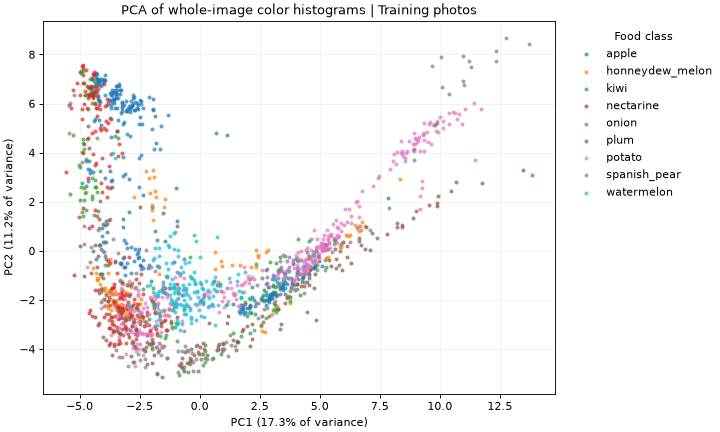

Some apples cluster in the upper left, and many potatoes extend to the right. Several classes overlap in the middle. Together, the two axes capture **28.6%** of the variation in the standardized histograms, so we see only part of how the photos differ. The experiment above uses 33 components to evaluate classification, while this plot uses two components to explore the data.

#### Recreate the plot

Run Sections 1 and 2 first to load the split and build the histograms. Then run the cell below.

1. **Choose the rows.** `feature_tables["Whole image"][is_training]` selects the histogram rows for the training photos. The food names are kept in a separate list.
2. **Turn 96 numbers into two.** `StandardScaler` puts the histogram columns on a comparable scale. PCA combines them into two coordinates per photo, like an x and y position on a map.
3. **Draw the dots.** The table pairs each photo's coordinates with its food name. The plot uses that name to choose the dot's color. The percentages on the axes show how much of the variation each coordinate captures.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Use the whole-image color histograms already calculated in Section 2.
pca_histograms = feature_tables["Whole image"][is_training]
pca_food_labels = labels[is_training]

scaled_histograms = StandardScaler().fit_transform(pca_histograms)
plot_pca = PCA(n_components=2)
coordinates = plot_pca.fit_transform(scaled_histograms)

pca_points = pd.DataFrame(coordinates, columns=["PC1", "PC2"])
pca_points["Food class"] = pca_food_labels

pca_figure, pca_axis = plt.subplots(figsize=(9, 5.4), layout="constrained")
pca_palette = plt.get_cmap("tab20")
color_indices = [0, 2, 4, 6, 8, 10, 12, 14, 18]

for (food, points), color_index in zip(pca_points.groupby("Food class"), color_indices):
    pca_axis.scatter(
        points["PC1"], points["PC2"], color=pca_palette(color_index),
        s=13, alpha=0.7, linewidths=0, label=food
    )

pc1_variation, pc2_variation = plot_pca.explained_variance_ratio_
pca_axis.set_title("PCA of whole-image color histograms | Training photos")
pca_axis.set_xlabel(f"PC1 ({pc1_variation:.1%} of variance)")
pca_axis.set_ylabel(f"PC2 ({pc2_variation:.1%} of variance)")
pca_axis.legend(title="Food class", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
pca_axis.grid(alpha=0.17)
pca_axis.set_axisbelow(True)
plt.show()
plt.close(pca_figure)

## 5. Where Does Cropping Help?

### 5.1 Crop First, Then Resize

A crop keeps a rectangle from the photo. We estimate the background from the original corners, find pixels that differ from it, and draw a box around those pixels with a 32-pixel margin. A background speck can make the box too wide, and food close to the background color can be missed.

We compare **whole photo → resize** with **crop → resize**. Both versions fit within **64 × 48 pixels** and keep their proportions. The histogram counts all pixels in the resized result, which gives 96 features even when one crop is narrower than another. The previews show training photos.

In [10]:
background_threshold = 50
corner_size = 40
crop_margin = 32

def estimate_crop_box(image, threshold, corner_size, margin):
    pixels = np.asarray(image, dtype="float32")

    top_left = pixels[:corner_size, :corner_size]
    top_right = pixels[:corner_size, -corner_size:]
    bottom_left = pixels[-corner_size:, :corner_size]
    bottom_right = pixels[-corner_size:, -corner_size:]

    corner_pixels = np.concatenate([
        top_left.reshape(-1, 3),
        top_right.reshape(-1, 3),
        bottom_left.reshape(-1, 3),
        bottom_right.reshape(-1, 3)
    ])
    background_color = np.median(corner_pixels, axis=0)

    color_difference = np.abs(pixels - background_color)
    largest_difference = color_difference.max(axis=2)
    foreground_mask = largest_difference > threshold

    row_positions, column_positions = np.where(foreground_mask)

    if len(column_positions) == 0:
        crop_box = (0, 0, image.width, image.height)
    else:
        left = max(0, int(column_positions.min()) - margin)
        top = max(0, int(row_positions.min()) - margin)
        right = min(image.width, int(column_positions.max()) + 1 + margin)
        bottom = min(image.height, int(row_positions.max()) + 1 + margin)
        crop_box = (left, top, right, bottom)

    return crop_box, foreground_mask, background_color

data/raw_images/fuji_apple/fuji_apple_001.jpg
data/raw_images/kiwi/kiwi_001.jpg
data/raw_images/plum/plum_002.jpg


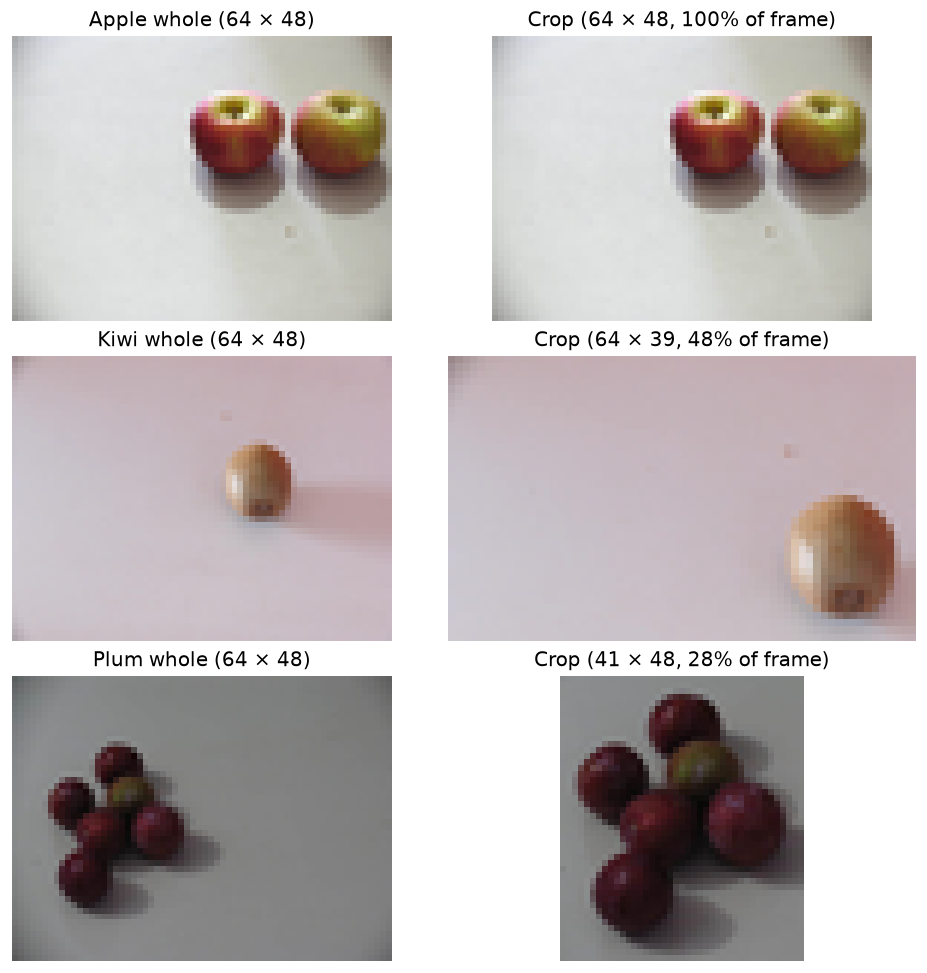

In [11]:
from PIL import ImageOps
import matplotlib.pyplot as plt

crop_resize_limit = (64, 48)


def resize_for_crop_experiment(photo):
    return ImageOps.contain(photo, crop_resize_limit, Image.Resampling.LANCZOS)


def crop_for_experiment(photo):
    box, _, _ = estimate_crop_box(
        photo, threshold=background_threshold, corner_size=corner_size, margin=crop_margin
    )
    return photo.crop(box), box


training_examples = experiment_rows[experiment_rows["split"].eq("train")]
fig, axes = plt.subplots(3, 2, figsize=(8, 8), layout="constrained")
for row, food in enumerate(["apple", "kiwi", "plum"]):
    crop_preview_path = training_examples.loc[
        training_examples["target_class"].eq(food), "image_path"
    ].iloc[0]
    with Image.open(project_folder / crop_preview_path) as source:
        original_photo = source.convert("RGB")

    crop_preview, _ = crop_for_experiment(original_photo)
    whole_small = resize_for_crop_experiment(original_photo)
    crop_small = resize_for_crop_experiment(crop_preview)
    crop_share = (crop_preview.width * crop_preview.height) / (original_photo.width * original_photo.height)
    for ax, preview in zip(axes[row], [whole_small, crop_small]):
        ax.imshow(preview, interpolation="nearest")
        ax.axis("off")
    axes[row, 0].set_title(f"{food.title()} whole ({whole_small.width} × {whole_small.height})")
    axes[row, 1].set_title(f"Crop ({crop_small.width} × {crop_small.height}, {crop_share:.0%} of frame)")
    print(crop_preview_path)

plt.show()
plt.close(fig)

Both versions use the same training and validation photos. A crop that keeps the full frame gives identical features to the resized whole photo. Compare the first two rows of the score table to see what adding the crop changed. Mask 80 serves as a reference and used original-resolution pixels.

In [12]:
whole_resize_rows = []
crop_resize_rows = []
full_frame_crops = []

for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        photo = source.convert("RGB")

    cropped_photo, box = crop_for_experiment(photo)
    full_frame_crops.append(box == (0, 0, photo.width, photo.height))
    whole_pixels = np.asarray(resize_for_crop_experiment(photo)).reshape(-1, 3)
    crop_pixels = np.asarray(resize_for_crop_experiment(cropped_photo)).reshape(-1, 3)
    whole_resize_rows.append(rgb_histogram_features(whole_pixels))
    crop_resize_rows.append(rgb_histogram_features(crop_pixels))

resize_feature_tables = {
    "Whole image → resize": np.array(whole_resize_rows),
    "Crop → resize": np.array(crop_resize_rows)
}
full_frame_crops = np.array(full_frame_crops)
print("Feature table shape for each version:", resize_feature_tables["Crop → resize"].shape)
print("Full-frame crops in training:", full_frame_crops[is_training].sum(), "of", is_training.sum())
print("Full-frame crops in validation:", full_frame_crops[~is_training].sum(), "of", (~is_training).sum())

Feature table shape for each version: (1803, 96)
Full-frame crops in training: 518 of 1603
Full-frame crops in validation: 71 of 200


In [13]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

resize_class_names = sorted(split_table["target_class"].unique())
resize_results = []
for name, features in resize_feature_tables.items():
    resize_model = LogisticRegression(max_iter=1000)
    resize_model.fit(features[is_training], labels[is_training])
    resize_predictions = resize_model.predict(features[~is_training])
    resize_scores = evaluate_predictions(labels[~is_training], resize_predictions, resize_class_names)
    resize_results.append({
        "Image preparation": name,
        "Validation accuracy": resize_scores["accuracy"],
        "Validation macro-F1": resize_scores["macro_f1"],
        "Validation ROC-AUC": macro_ovr_auc(resize_model, features[~is_training], labels[~is_training])
    })

mask_reference = validation_scores.loc[validation_scores["Image preparation"].eq("Mask 80")].iloc[0]
resize_results.append({
    "Image preparation": "Mask 80 (reference)",
    "Validation accuracy": mask_reference["Accuracy"],
    "Validation macro-F1": mask_reference["Macro-F1"],
    "Validation ROC-AUC": mask_reference["ROC-AUC"]
})
resize_comparison = pd.DataFrame(resize_results)
display(resize_comparison.round(4))

,Image preparation,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Whole image → resize,0.725,0.6009,0.9240
1,Crop → resize,0.695,0.5704,0.9346
2,Mask 80 (reference),0.720,0.6648,0.9419


**Result.** Adding the crop lowered validation accuracy from **72.5% to 69.5%** and macro-F1 from **0.601 to 0.570**. The crop kept the full frame for **71 of 200** validation photos. ROC-AUC rose from **0.9240 to 0.9346**. The two metrics tell different stories: ranking improved, while the final food guesses scored worse. Mask 80 still had the highest macro-F1 and ROC-AUC in this table.

### 5.2 Mask 80 First, Then Crop and Resize

We start with the Mask 80 rule on the original photo. Then we crop to the smallest rectangle containing every kept pixel. At that point the histogram would stay the same, because the crop keeps every pixel that already counted.

#### Learning note – Shrink the photo and its stencil together

We resize the crop to fit within **64 × 48 pixels** and resize its mask to the exact same dimensions. Nearest-neighbor resizing copies a source pixel and its mask decision together. This keeps the kept and skipped pixels aligned and avoids blending skipped colors into the kept ones. We count only resized pixels marked as kept. Some kept pixels can disappear when the photo is made smaller.

If Mask 80 keeps zero pixels in the original photo, we use the whole-image histogram, as in Section 2. If resizing leaves zero kept pixels, we use the original Mask 80 histogram for that photo. The output counts both cases.

Both models use the same 1,603 training photos, 200 validation photos, and logistic regression settings. The Mask 80 row comes from Section 3. A crop around the kept pixels retains them all before resizing, so any change in the histogram comes from resizing within that crop.

In [20]:
from PIL import ImageOps
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

mask_crop_limit = (64, 48)


def mask_crop_resize_features(photo):
    original_pixels = np.asarray(photo)
    kept = background_color_distance(original_pixels).reshape(photo.height, photo.width) > 80
    pixel_mask = Image.fromarray(kept)
    crop_box = pixel_mask.getbbox()
    if crop_box is None:
        return rgb_histogram_features(original_pixels.reshape(-1, 3)), "Empty original mask"

    small_photo = ImageOps.contain(photo.crop(crop_box), mask_crop_limit, Image.Resampling.NEAREST)
    small_mask = pixel_mask.crop(crop_box).resize(small_photo.size, Image.Resampling.NEAREST)
    small_kept = np.asarray(small_mask, dtype=bool)
    selected_pixels = np.asarray(small_photo)[small_kept]
    if len(selected_pixels) == 0:
        return rgb_histogram_features(original_pixels[kept]), "Empty resized mask"

    return rgb_histogram_features(selected_pixels), "No fallback"


mask_crop_rows = []
mask_crop_fallbacks = []
for image_path in experiment_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        mask_crop_photo = source.convert("RGB")

    features, fallback = mask_crop_resize_features(mask_crop_photo)
    mask_crop_rows.append(features)
    mask_crop_fallbacks.append(fallback)

mask_crop_table = np.array(mask_crop_rows)
mask_crop_fallbacks = np.array(mask_crop_fallbacks)
print("Feature table shape:", mask_crop_table.shape)
for reason in ["Empty original mask", "Empty resized mask"]:
    fallback_rows = mask_crop_fallbacks == reason
    print(reason, "- training:", fallback_rows[is_training].sum(),
          "- validation:", fallback_rows[~is_training].sum())

Feature table shape: (1803, 96)
Empty original mask - training: 15 - validation: 2
Empty resized mask - training: 0 - validation: 0


In [21]:
mask_crop_model = LogisticRegression(max_iter=1000)
mask_crop_model.fit(mask_crop_table[is_training], labels[is_training])
mask_crop_validation_features = mask_crop_table[~is_training]
mask_crop_labels = labels[~is_training]
mask_crop_guesses = mask_crop_model.predict(mask_crop_validation_features)
mask_crop_class_names = sorted(split_table["target_class"].unique())
mask_crop_scores = evaluate_predictions(mask_crop_labels, mask_crop_guesses, mask_crop_class_names)
mask_crop_auc = macro_ovr_auc(mask_crop_model, mask_crop_validation_features, mask_crop_labels)

original_mask_80 = validation_scores.loc[validation_scores["Image preparation"].eq("Mask 80")].iloc[0]
mask_crop_comparison = pd.DataFrame([
    {
        "Image preparation": "Mask 80",
        "Validation accuracy": original_mask_80["Accuracy"],
        "Validation macro-F1": original_mask_80["Macro-F1"],
        "Validation ROC-AUC": original_mask_80["ROC-AUC"]
    },
    {
        "Image preparation": "Mask 80 → crop → resize",
        "Validation accuracy": mask_crop_scores["accuracy"],
        "Validation macro-F1": mask_crop_scores["macro_f1"],
        "Validation ROC-AUC": mask_crop_auc
    }
])
display(mask_crop_comparison.round(4))

,Image preparation,Validation accuracy,Validation macro-F1,Validation ROC-AUC
0,Mask 80,0.72,0.6648,0.9419
1,Mask 80 → crop → resize,0.72,0.6658,0.9398


**Result.** Both versions correctly classified **144 of 200** validation photos. Adding crop and resize moved macro-F1 from **0.6648 to 0.6658** and ROC-AUC from **0.9419 to 0.9398**. The differences are small on this split. We keep the original Mask 80 as the baseline.

## 6. Check for Background and Capture-Time Shortcuts

The histogram can capture colors from the food or its surroundings. Before reading the test score, we check how much information is in the corners and how much performance changes when nearby capture times stay together.

#### Learning note – Try changing what the model gets to see

**Corners only.** We build a histogram from the four corner patches and compare a classifier with a dummy model that guesses using the training class frequencies. If the corner model does better, the corners contain information about the labels. The patches can contain food as well as background, so this is evidence of a possible shortcut.

**Random folds versus capture-time groups.** We score the same balanced Mask 80 model two ways. The first uses the random stratified folds from Section 3.3. The second keeps all photos from each five-minute capture interval in one fold, following the grouping explored in EDA. The intervals approximate photography sessions. A score change shows how sensitive our results are to which photos stay together.

In [19]:
from datetime import datetime
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedGroupKFold

corner_rows = []
capture_groups = []
for image_path in review_rows["image_path"]:
    with Image.open(project_folder / image_path) as source:
        exif = source.getexif()
        capture_value = exif.get(36867) or exif.get_ifd(0x8769).get(36867)
        photo = np.asarray(source.convert("RGB"))

    if capture_value is None:
        raise ValueError(f"Missing EXIF capture time for {image_path}")
    capture_time = datetime.strptime(str(capture_value), "%Y:%m:%d %H:%M:%S")
    five_minute_start = capture_time.replace(minute=(capture_time.minute // 5) * 5, second=0)
    capture_groups.append(five_minute_start.isoformat())

    height, width, _ = photo.shape
    corner_height = max(1, int(height * 0.10))
    corner_width = max(1, int(width * 0.10))
    corners = [photo[:corner_height, :corner_width], photo[:corner_height, -corner_width:],
               photo[-corner_height:, :corner_width], photo[-corner_height:, -corner_width:]]
    corner_pixels = np.concatenate([corner.reshape(-1, 3) for corner in corners])
    corner_rows.append(rgb_histogram_features(corner_pixels))

corner_features = np.array(corner_rows)
capture_groups = np.array(capture_groups)
mask_80_training = review_features["Mask 80"]
group_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
group_folds = list(group_splitter.split(mask_80_training, review_labels, capture_groups))

print("Five-minute training groups:", len(set(capture_groups)))
for number, (fit_indices, score_indices) in enumerate(group_folds, start=1):
    shared_groups = set(capture_groups[fit_indices]) & set(capture_groups[score_indices])
    held_out_classes = set(review_labels[score_indices])
    assert not shared_groups
    assert held_out_classes == set(review_class_names)
    print(f"Grouped fold {number}: {len(score_indices)} photos, {len(held_out_classes)} foods")

balanced_model = LogisticRegression(max_iter=1000, class_weight="balanced")
shortcut_checks = [
    ("Guess from class frequencies", DummyClassifier(strategy="stratified", random_state=42), corner_features, review_folds),
    ("Corners only, random folds", balanced_model, corner_features, review_folds),
    ("Mask 80, random folds", balanced_model, mask_80_training, review_folds),
    ("Mask 80, grouped folds", balanced_model, mask_80_training, group_folds)
]
shortcut_results = []
for name, estimator, features, folds in shortcut_checks:
    fold_scores, _ = score_review_folds(estimator, features, folds)
    shortcut_results.append({
        "Check": name,
        "Mean macro-F1": fold_scores[:, 1].mean(),
        "Macro-F1 SD": fold_scores[:, 1].std(ddof=1),
        "Mean ROC-AUC": fold_scores[:, 2].mean(),
        "ROC-AUC SD": fold_scores[:, 2].std(ddof=1)
    })
shortcut_comparison = pd.DataFrame(shortcut_results)
display(shortcut_comparison.round(3))

Five-minute training groups: 104
Grouped fold 1: 313 photos, 9 foods
Grouped fold 2: 323 photos, 9 foods
Grouped fold 3: 321 photos, 9 foods
Grouped fold 4: 323 photos, 9 foods
Grouped fold 5: 323 photos, 9 foods


,Check,Mean macro-F1,Macro-F1 SD,Mean ROC-AUC,ROC-AUC SD
0,Guess from class frequencies,0.130,0.002,0.511,0.001
1,"Corners only, random folds",0.652,0.013,0.928,0.011
2,"Mask 80, random folds",0.654,0.015,0.943,0.003
3,"Mask 80, grouped folds",0.528,0.072,0.857,0.040


**What the shortcut checks showed.** Corners alone scored **0.652 macro-F1** and **0.928 ROC-AUC**, compared with **0.130** and **0.511** for frequency-based guesses. The corners carry substantial label information, and they can contain both food and background.

Balanced Mask 80 went from **0.654 macro-F1 and 0.943 ROC-AUC** in random folds to **0.528 and 0.857** in capture-time grouped folds. The score is sensitive to which photos stay together. The five-minute intervals are approximate sessions and the grouped folds can differ in composition. Keep that limitation in mind when reading the original test result below.

## 7. Report the Original Baseline on Test

The test score belongs to the original Mask 80 model with default class weights chosen on validation in Section 3. The cross-validation and shortcut scores come from held-out folds of the training photos.

### 7.1 Prepare the Reserved Photos

Each of the 200 test photos gets the same 96-feature Mask 80 preparation. A photo uses the whole-image histogram if the mask skips every pixel, just as in training and validation.

In [14]:
def mask_80_feature_table(image_paths):
    rows = []
    empty_masks = 0

    for image_path in image_paths:
        with Image.open(project_folder / image_path) as source:
            image = np.array(source.convert("RGB"))

        pixels = image.reshape(-1, 3)
        color_distance = background_color_distance(image)
        selected_pixels = pixels[color_distance > 80]

        if len(selected_pixels) == 0:
            selected_pixels = pixels
            empty_masks += 1

        rows.append(rgb_histogram_features(selected_pixels))

    return np.array(rows), empty_masks


test_rows = split_table[split_table["split"].eq("test")]
X_test, test_empty_masks = mask_80_feature_table(test_rows["image_path"])
y_test = test_rows["target_class"].to_numpy()

print("Test feature table shape:", X_test.shape)
print("Empty test masks that used the whole image:", test_empty_masks)

Test feature table shape: (200, 96)
Empty test masks that used the whole image: 5


### 7.2 Score the Guesses

The classifier fits on the 1,603 training photos and predicts labels for the 200 test photos. `evaluate_predictions()` takes the correct labels, the guesses in matching photo order, and the full class list. It returns accuracy, macro-F1, and a confusion matrix. The group can use the same function for every model.

In [15]:
from sklearn.linear_model import LogisticRegression
from src.evaluate import evaluate_predictions

X_final_train = feature_tables["Mask 80"][is_training]
y_final_train = labels[is_training]

final_model = LogisticRegression(max_iter=1000)
final_model.fit(X_final_train, y_final_train)
test_predictions = final_model.predict(X_test)

test_class_names = sorted(split_table["target_class"].unique())
test_scores = evaluate_predictions(y_test, test_predictions, test_class_names)
test_accuracy = test_scores["accuracy"]
test_macro_f1 = test_scores["macro_f1"]
test_auc = macro_ovr_auc(final_model, X_test, y_test)

print("Training photos:", len(y_final_train))
print("Test photos:", len(y_test))
print("Correct test guesses:", np.count_nonzero(y_test == test_predictions))
print(f"Test accuracy: {test_accuracy:.1%}")
print(f"Test macro-F1: {test_macro_f1:.3f}")
print(f"Test macro one-vs-rest ROC-AUC: {test_auc:.3f}")

Training photos: 1603
Test photos: 200
Correct test guesses: 148
Test accuracy: 74.0%
Test macro-F1: 0.652
Test macro one-vs-rest ROC-AUC: 0.940


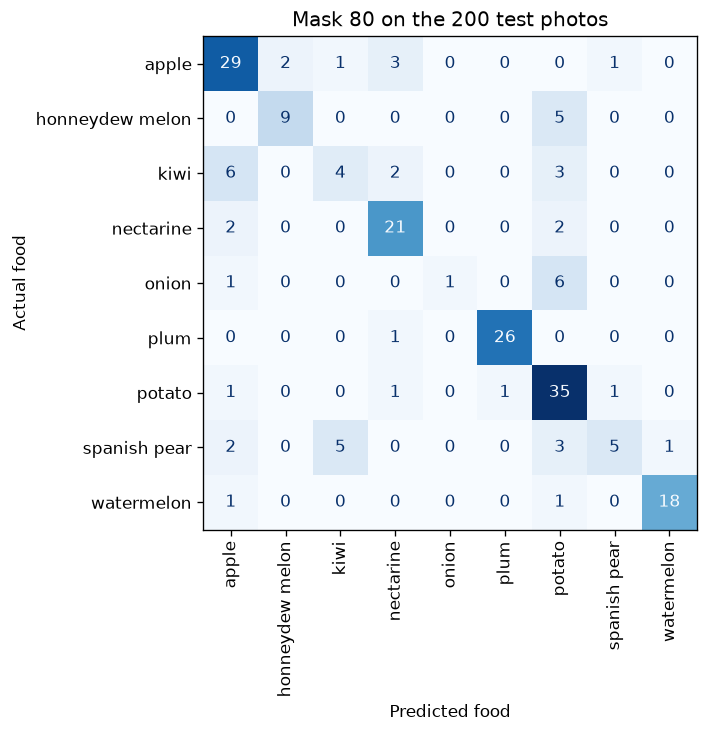

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

test_confusion = test_scores["confusion_matrix"]
test_display_names = [name.replace("_", " ") for name in test_class_names]

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ConfusionMatrixDisplay(test_confusion, display_labels=test_display_names).plot(
    ax=ax, cmap="Blues", colorbar=False, xticks_rotation=90
)
ax.set_title("Mask 80 on the 200 test photos")
ax.set_xlabel("Predicted food")
ax.set_ylabel("Actual food")
plt.show()
plt.close(fig)

**Final baseline.** Mask 80 correctly classified **148 of 200** test photos, with **74.0% accuracy**, **0.652 macro-F1**, and **0.940 macro one-vs-rest ROC-AUC**. The most frequent mistake was predicting apple for **6 of 15 kiwi photos**. The split keeps identified near-duplicates in training, but related photos may still appear across splits. Photos from a different setting would give a separate check of generalization.

## 8. What the Group Can Reuse

- **Baseline for comparison.** Use the original Mask 80 scores on the matching split. Validation was **72.0% accuracy, 0.665 macro-F1, and 0.942 ROC-AUC**. Test was **74.0%, 0.652, and 0.940**.
- **Shared evaluation.** Use `evaluate_predictions()` with the group's nine labels and one guess per photo in split-file order. [src/evaluate.py](../src/evaluate.py)
- **Shared image loader.** `load_image()` returns a resized RGB grid with values from 0 to 1 for models that work with image arrays. Section 2 shows the separate preparation used by the histogram baseline. [src/preprocess.py](../src/preprocess.py)
- **Shared split.** Use the same image paths, labels, and split assignments for every model. [data/dataset_split.csv](../data/dataset_split.csv)